# IND320 — Project Work, Part 2

**GitHub repository:** https://github.com/isach07/IND320_isachstevik

**Streamlit app:** https://ind320isachstevik-dsj69wxyp9oamezekyfwal.streamlit.app

**Video presentation:** _link coming_

In [ ]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

## Cassandra with Spark

Cassandra runs in a Docker container (`my_cassandra`, image `cassandra`), and Spark runs locally
and connects to it on localhost:9042 through the Spark Cassandra connector
(`spark-cassandra-connector_2.12:3.5.1`, matching `pyspark==3.5.1`).

Start Cassandra before running these cells: open Docker Desktop and start `my_cassandra`,
or run `docker start my_cassandra` in the terminal.

In [ ]:
import os
from pyspark.sql import SparkSession

# Spark needs Java; use the Java 17 that Homebrew installed with Cassandra
os.environ["JAVA_HOME"] = "/opt/homebrew/opt/openjdk@17"

# Keep Spark on localhost so it doesn't depend on which Wi-Fi/hotspot I'm on
os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"

spark = (
    SparkSession.builder.appName("IND320")
    .master("local[*]")
    .config("spark.jars.packages", "com.datastax.spark:spark-cassandra-connector_2.12:3.5.1")
    .config("spark.cassandra.connection.host", "127.0.0.1")
    .config("spark.cassandra.connection.port", "9042")
    # lets us create keyspaces and tables with Spark SQL through the "cass" catalog
    .config("spark.sql.extensions", "com.datastax.spark.connector.CassandraSparkExtensions")
    .config("spark.sql.catalog.cass", "com.datastax.spark.connector.datasource.CassandraCatalog")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")

In [4]:
# keyspace for the project; one table per API dataset is added later
KEYSPACE = "ind320"

spark.sql(f"CREATE DATABASE IF NOT EXISTS cass.{KEYSPACE} "
          "WITH DBPROPERTIES (class='SimpleStrategy', replication_factor='1')")
spark.sql("SHOW NAMESPACES IN cass").show()

+---------+
|namespace|
+---------+
|   ind320|
+---------+



In [5]:
# helpers for moving Spark data frames in and out of Cassandra
def write_cassandra(sdf, table, keyspace=KEYSPACE):
    (sdf.write.format("org.apache.spark.sql.cassandra")
        .options(keyspace=keyspace, table=table)
        .mode("append")
        .save())


def read_cassandra(table, keyspace=KEYSPACE):
    return (spark.read.format("org.apache.spark.sql.cassandra")
            .options(keyspace=keyspace, table=table)
            .load())

In [6]:
# Create a small test table through Spark's Cassandra catalog.
# PARTITIONED BY sets the partition key (Cassandra needs a primary key on every table).
spark.sql(f"""
    CREATE TABLE IF NOT EXISTS cass.{KEYSPACE}.smoke_test (
        id INT,
        value STRING
    )
    USING cassandra
    PARTITIONED BY (id)
""")
spark.sql(f"SHOW TABLES IN cass.{KEYSPACE}").show()

+---------+----------+-----------+
|namespace| tableName|isTemporary|
+---------+----------+-----------+
|   ind320|smoke_test|      false|
+---------+----------+-----------+



## MongoDB

In [17]:
# MongoDB connection test.
# The connection string lives in ../.streamlit/secrets.toml (gitignored), shared with the Streamlit app.
# The notebook runs from notebooks/, so the path goes one level up to the project root.
import tomllib
from pathlib import Path
from pymongo import MongoClient

secrets_path = Path("..") / ".streamlit" / "secrets.toml"
with open(secrets_path, "rb") as f:
    secrets = tomllib.load(f)

client = MongoClient(secrets["mongo"]["uri"])
client.admin.command("ping")          # raises an error if the cluster can't be reached
print("Connected to MongoDB")

mdb = client["ind320"]


Connected to MongoDB
[{'hello': 'mongo'}]


## Reservoirdata from API

In [15]:
# NVE's public reservoir statistics API (no key needed)
NVE_BASE = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk"

def nve_get(endpoint):
    """GET one endpoint from the Magasinstatistikk API and return the parsed JSON."""
    resp = requests.get(f"{NVE_BASE}/{endpoint}", timeout=30)
    resp.raise_for_status()          # stop with a clear error if the API call fails
    return resp.json()

def flatten_areas(data, group=None):
    """Collect every area record (anything with an 'omrType') into a flat list of rows."""
    rows = []
    if isinstance(data, list):
        for item in data:
            rows += flatten_areas(item, group)
    elif isinstance(data, dict):
        if "omrType" in data:
            rows.append({**data, "gruppe": group})
        else:
            for key, value in data.items():
                rows += flatten_areas(value, key)
    return rows

# Which areas of Norway does the API cover? ("HentOmråder" is URL-encoded because of the å)
areas = pd.DataFrame(flatten_areas(nve_get("HentOmr%C3%A5der")))
areas

,navn,navn_langt,beskrivelse,omrType,omrnr,gruppe
0,Norge,Norge,Hele landet,NO,0,land
1,NO 1,Elspotområde 1,Sørøst-Norge. Omfatter østlige del av Østlande...,EL,1,elspot
2,NO 2,Elspotområde 2,Sørvest-Norge. Omfatter mesteparten av Vestfol...,EL,2,elspot
3,NO 3,Elspotområde 3,Midt-Norge. Omfatter nordre og vestlige del av...,EL,3,elspot
4,NO 4,Elspotområde 4,Nord-Norge. Omfatter resten av Trøndelag og No...,EL,4,elspot
5,NO 5,Elspotområde 5,Vest-Norge. Omfatter midtre del av Vestland op...,EL,5,elspot
6,VASS1,Vassdragsområde 1,"Sørøst-Norge. Østlandet, Agder og deler av Rog...",VASS,1,vassdrag
7,VASS2,Vassdragsområde 2,Vest-Norge. Resten av Rogaland og Vestland.,VASS,2,vassdrag
8,VASS3,Vassdragsområde 3,"Midt-Norge. Møre og Romsdal, Trøndelag og sørl...",VASS,3,vassdrag
9,VASS4,Vassdragsområde 4,Nord-Norge. Resten av Nordland og nordover.,VASS,4,vassdrag


In [2]:
# One call returns every week for every area (the same data that used to be in reservoirs.csv)
df = pd.DataFrame(nve_get("HentOffentligData"))

# dato_Id comes as text, e.g. "2026-10-11"; convert it to a real date
df["dato_Id"] = pd.to_datetime(df["dato_Id"])

# 0001-01-01T00:00:00 is a placeholder for "no date", so make it missing (as in part 1)
df["neste_Publiseringsdato"] = pd.to_datetime(
    df["neste_Publiseringsdato"].replace("0001-01-01T00:00:00", None)
)

# English column names, same as part 1
df = df.rename(columns={
    "dato_Id": "date",
    "omrType": "area_type",
    "omrnr": "area_number",
    "iso_aar": "iso_year",
    "iso_uke": "iso_week",
    "fyllingsgrad": "fill_ratio",
    "kapasitet_TWh": "capacity_twh",
    "fylling_TWh": "filling_twh",
    "neste_Publiseringsdato": "next_publish_date",
    "fyllingsgrad_forrige_uke": "fill_ratio_prev_week",
    "endring_fyllingsgrad": "fill_ratio_change",
})

# one label per area, e.g. "EL 1", and sort so each area's rows are in date order
df["area"] = df["area_type"] + " " + df["area_number"].astype(str)
df = df.sort_values(["area", "date"]).reset_index(drop=True)

print(f"Shape: {df.shape}")
print(f"Date range: {df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")
print(f"Areas: {sorted(df['area'].unique())}")
df.head()

Shape: (14922, 12)
Date range: 1995-01-08 to 2026-10-11
Areas: ['EL 1', 'EL 2', 'EL 3', 'EL 4', 'EL 5', 'NO 0', 'VASS 1', 'VASS 2', 'VASS 3']


,date,area_type,area_number,iso_year,iso_week,fill_ratio,capacity_twh,filling_twh,next_publish_date,fill_ratio_prev_week,fill_ratio_change,area
0,1995-01-08,EL,1,1995,1,0.617574,6.003264,3.707457,NaT,0.583705,0.033869,EL 1
1,1995-01-15,EL,1,1995,2,0.579205,6.003264,3.477117,NaT,0.617574,-0.038369,EL 1
2,1995-01-22,EL,1,1995,3,0.546713,6.003264,3.282063,NaT,0.579205,-0.032491,EL 1
3,1995-01-29,EL,1,1995,4,0.504545,6.003264,3.028916,NaT,0.546713,-0.042168,EL 1
4,1995-02-05,EL,1,1995,5,0.465335,6.003264,2.793528,NaT,0.504545,-0.039210,EL 1


## NVE magasinstatestikk API

_Describe the task here._

### Reorganizing by area

Same as in part 1, but with the data from the API: the data is pivoted so each area gets its own column, with one row per date in time order. The average is taken over the five price areas (`EL 1`–`EL 5`), which together cover all of Norway, so no region is counted twice.

In [9]:
# reorganize: one row per date, one column per area
by_area = df.pivot(index="date", columns="area", values="fill_ratio")
by_area["EL average"] = by_area[["EL 1", "EL 2", "EL 3", "EL 4", "EL 5"]].mean(axis=1)
by_area

area,EL 1,EL 2,EL 3,EL 4,EL 5,NO 0,VASS 1,VASS 2,VASS 3,EL average
date,,,,,,,,,,
1995-01-08,0.617574,0.630947,0.602376,0.558864,0.616448,0.607988,0.635440,0.608856,0.566906,0.605242
1995-01-15,0.579205,0.605742,0.569943,0.540690,0.588414,0.582088,0.604392,0.588298,0.544191,0.576799
1995-01-22,0.546713,0.592606,0.542203,0.522262,0.562996,0.562121,0.584735,0.570423,0.522262,0.553356
1995-01-29,0.504545,0.566928,0.508148,0.501427,0.531442,0.534222,0.554386,0.542517,0.498039,0.522498
1995-02-05,0.465335,0.539795,0.473883,0.481138,0.500549,0.506221,0.521019,0.519871,0.473426,0.492140
...,...,...,...,...,...,...,...,...,...,...
2026-09-13,0.725221,0.469039,0.652494,0.900141,0.650104,0.642904,0.576660,0.529515,0.829082,0.679400
2026-09-20,0.743088,0.497997,0.680705,0.901826,0.688036,0.666386,0.601457,0.570847,0.835602,0.702330
2026-09-27,0.750023,0.511455,0.715288,0.898011,0.707345,0.678552,0.615298,0.585406,0.843417,0.716425


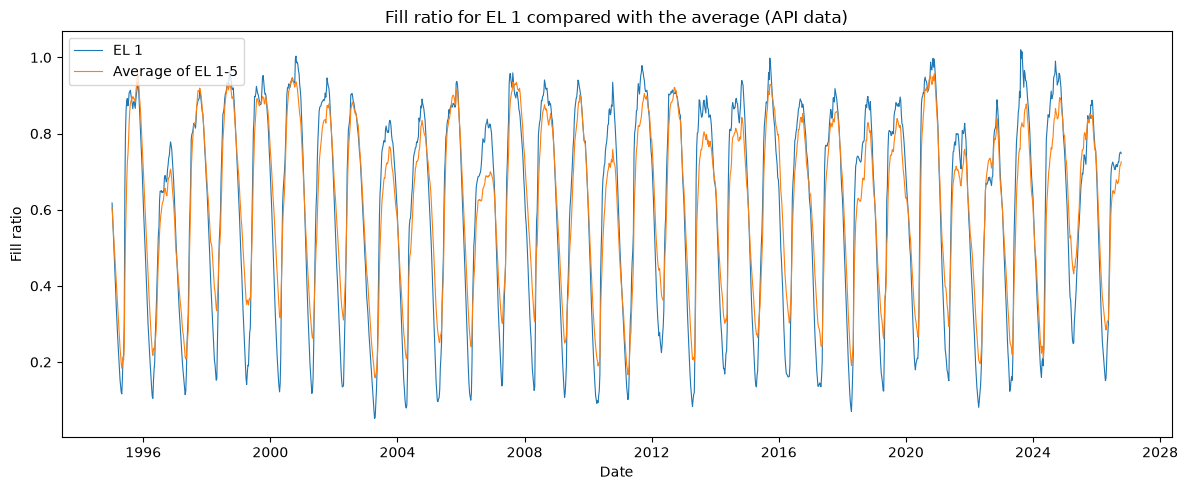

In [10]:
# choose the area to look at: NO 0, EL 1-5 or VASS 1-3
AREA = "EL 1"

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(by_area.index, by_area[AREA], linewidth=0.8, label=AREA)
ax.plot(by_area.index, by_area["EL average"], linewidth=0.8, label="Average of EL 1-5")
ax.set_title(f"Fill ratio for {AREA} compared with the average (API data)")
ax.set_xlabel("Date")
ax.set_ylabel("Fill ratio")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

### All columns for the chosen area

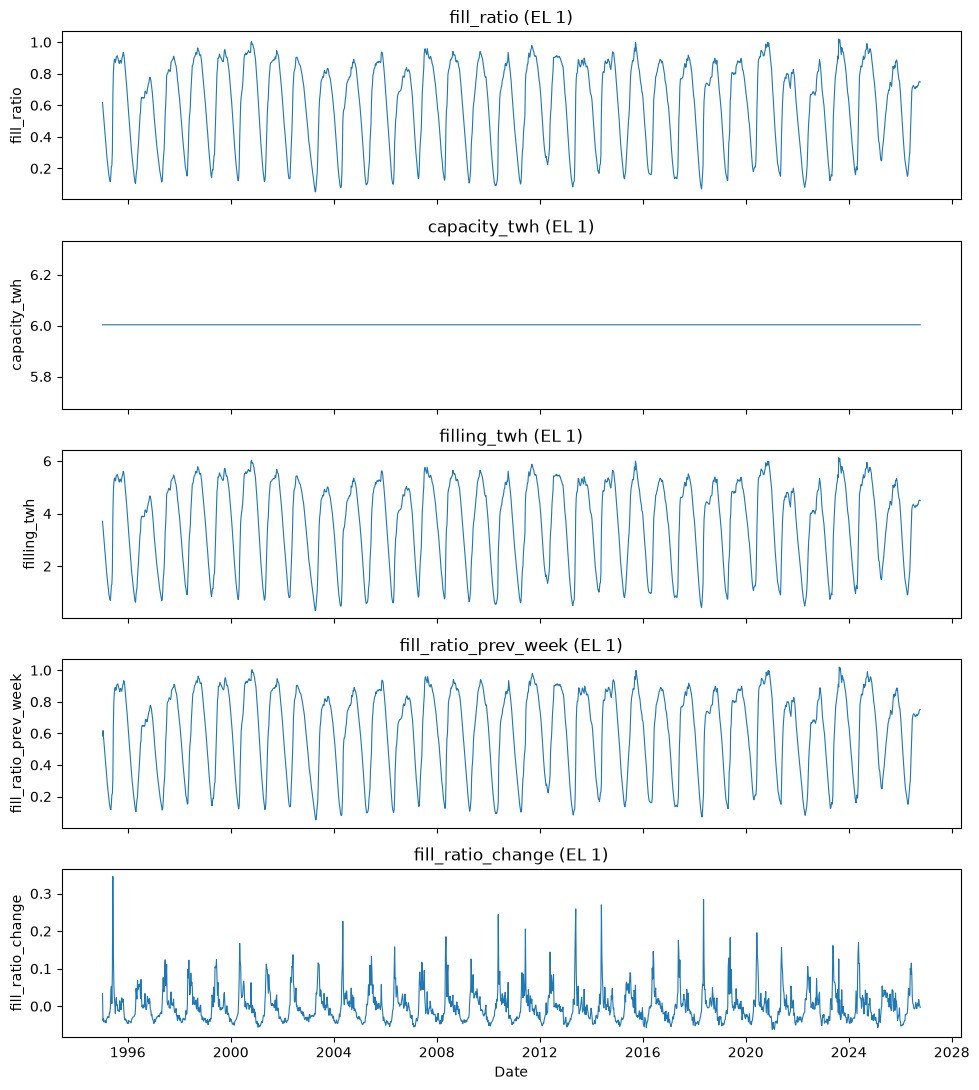

In [11]:
# plotting each column for the chosen area in its own subplot, sharing the date axis
area_df = df[df["area"] == AREA]

# area_number, iso_year and iso_week are identifiers, not measurements
numeric_cols = area_df.select_dtypes("number").columns.drop(["area_number", "iso_year", "iso_week"])

fig, axes = plt.subplots(len(numeric_cols), 1, figsize=(10, 2.2 * len(numeric_cols)), sharex=True)
for ax, col in zip(axes, numeric_cols):
    ax.plot(area_df["date"], area_df[col], linewidth=0.8)
    ax.set_title(f"{col} ({AREA})")
    ax.set_ylabel(col)
axes[-1].set_xlabel("Date")
plt.tight_layout()
plt.show()

### Plotting all columns together

Since the columns have very different scales (e.g. `fill_ratio` is between 0 and 1, while `capacity_twh` is in the tens), each column is normalized to a 0–1 range before plotting together, so they can be compared on one chart.

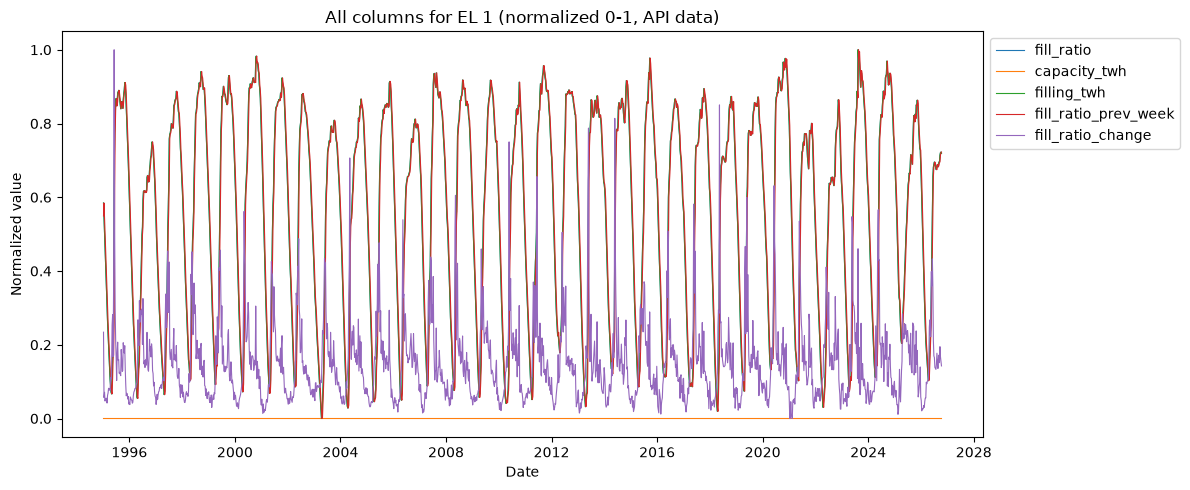

In [12]:
# capacity_twh is constant, so its range is 0; use 1 instead to avoid dividing by zero
value_range = (area_df[numeric_cols].max() - area_df[numeric_cols].min()).replace(0, 1)
normalized = (area_df[numeric_cols] - area_df[numeric_cols].min()) / value_range

fig, ax = plt.subplots(figsize=(12, 5))
for col in numeric_cols:
    ax.plot(area_df["date"], normalized[col], label=col, linewidth=0.8)
ax.set_title(f"All columns for {AREA} (normalized 0-1, API data)")
ax.set_xlabel("Date")
ax.set_ylabel("Normalized value")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

## ENTSO-E cross-border flows

In [18]:
# Quick check that the ENTSO-E token works: one day of flow on one connection
from entsoe import EntsoePandasClient

entsoe_client = EntsoePandasClient(api_key=secrets["entsoe"]["token"])
test = entsoe_client.query_crossborder_flows(
    "NO_2", "DK_1",
    start=pd.Timestamp("2025-01-01", tz="Europe/Oslo"),
    end=pd.Timestamp("2025-01-02", tz="Europe/Oslo"),
)
test.head()

2025-01-01 00:00:00+01:00    0.0
2025-01-01 01:00:00+01:00    0.0
2025-01-01 02:00:00+01:00    0.0
2025-01-01 03:00:00+01:00    0.0
2025-01-01 04:00:00+01:00    0.0
Freq: 60min, dtype: float64

In [19]:
# the opposite direction should have values where the first one is 0
entsoe_client.query_crossborder_flows(
    "DK_1", "NO_2",
    start=pd.Timestamp("2025-01-01", tz="Europe/Oslo"),
    end=pd.Timestamp("2025-01-02", tz="Europe/Oslo"),
).head()

2025-01-01 00:00:00+01:00    1604.1425
2025-01-01 01:00:00+01:00    1603.9600
2025-01-01 02:00:00+01:00    1585.1300
2025-01-01 03:00:00+01:00    1330.3925
2025-01-01 04:00:00+01:00    1237.3875
Freq: 60min, dtype: float64

In [20]:
# Cross-border physical flows between Norway and its neighbours, from ENTSO-E.
# Uses entsoe_client from the token test cell above.

# Norway's cross-border connections, as (Norwegian price area, neighbouring bidding zone)
CONNECTIONS = [
    ("NO_1", "SE_3"),
    ("NO_2", "DK_1"),
    ("NO_2", "NL"),
    ("NO_2", "DE_LU"),
    ("NO_2", "GB"),
    ("NO_3", "SE_2"),
    ("NO_4", "SE_1"),
    ("NO_4", "SE_2"),
    ("NO_4", "FI"),
]

# From 1 January two years ago until today, so the last two years are covered
# and the earlier years are complete (useful for the yearly pie chart)
end = pd.Timestamp.now(tz="Europe/Oslo").normalize()
start = pd.Timestamp(year=end.year - 2, month=1, day=1, tz="Europe/Oslo")

frames = []
for no_zone, other_zone in CONNECTIONS:
    # each connection has two directions: out of Norway and into Norway
    for from_zone, to_zone in [(no_zone, other_zone), (other_zone, no_zone)]:
        try:
            s = entsoe_client.query_crossborder_flows(from_zone, to_zone, start=start, end=end)
        except Exception as e:  # some connections (e.g. GB) may have no data
            print(f"Skipped {from_zone} -> {to_zone}: {e}")
            continue

        # Some areas switched from hourly to 15-minute values, so average per hour.
        # An hourly average in MW equals the energy in MWh for that hour.
        s = s.resample("h").mean()

        frames.append(pd.DataFrame({
            "connection": f"{no_zone}-{other_zone}",
            "from_zone": from_zone,
            "to_zone": to_zone,
            "time": s.index.tz_convert("UTC").tz_localize(None),  # store as plain UTC
            "flow_mwh": s.values,
        }))
        print(f"{from_zone} -> {to_zone}: {len(s)} hours")

flows = pd.concat(frames, ignore_index=True).dropna()
print(f"\nTotal rows: {len(flows)}")
flows.head()


NO_1 -> SE_3: 24527 hours
SE_3 -> NO_1: 24527 hours
NO_2 -> DK_1: 24527 hours
DK_1 -> NO_2: 24527 hours
NO_2 -> NL: 24527 hours
NL -> NO_2: 24527 hours
NO_2 -> DE_LU: 24527 hours
DE_LU -> NO_2: 24527 hours
NO_2 -> GB: 24527 hours
GB -> NO_2: 24527 hours
NO_3 -> SE_2: 24527 hours
SE_2 -> NO_3: 24527 hours
NO_4 -> SE_1: 24527 hours
SE_1 -> NO_4: 24527 hours
NO_4 -> SE_2: 24527 hours
SE_2 -> NO_4: 24527 hours
NO_4 -> FI: 24527 hours
FI -> NO_4: 24527 hours

Total rows: 441486


,connection,from_zone,to_zone,time,flow_mwh
0,NO_1-SE_3,NO_1,SE_3,2023-12-31 23:00:00,0.0
1,NO_1-SE_3,NO_1,SE_3,2024-01-01 00:00:00,0.0
2,NO_1-SE_3,NO_1,SE_3,2024-01-01 01:00:00,0.0
3,NO_1-SE_3,NO_1,SE_3,2024-01-01 02:00:00,0.0
4,NO_1-SE_3,NO_1,SE_3,2024-01-01 03:00:00,0.0


In [21]:
flows.to_parquet("flows.parquet")

In [22]:
flows.groupby(["connection", "from_zone", "to_zone"])["flow_mwh"].sum().div(1e6).round(2)

connection  from_zone  to_zone
NO_1-SE_3   NO_1       SE_3        4.32
            SE_3       NO_1       15.91
NO_2-DE_LU  DE_LU      NO_2        4.24
            NO_2       DE_LU      18.99
NO_2-DK_1   DK_1       NO_2        5.49
            NO_2       DK_1       20.12
NO_2-GB     GB         NO_2        2.09
            NO_2       GB         25.85
NO_2-NL     NL         NO_2        1.72
            NO_2       NL          7.09
NO_3-SE_2   NO_3       SE_2        1.84
            SE_2       NO_3        6.09
NO_4-FI     FI         NO_4        0.11
            NO_4       FI          0.81
NO_4-SE_1   NO_4       SE_1        3.51
            SE_1       NO_4        2.48
NO_4-SE_2   NO_4       SE_2        1.21
            SE_2       NO_4        0.94
Name: flow_mwh, dtype: float64

Write the flows into Cassandra with Spark

In [23]:
# Create the Cassandra table for the cross-border flows.
# Partition key: one partition per connection and direction (18 partitions).
# Clustering key: time, so each partition is stored in time order.
spark.sql(f"""
    CREATE TABLE IF NOT EXISTS cass.{KEYSPACE}.crossborder_flows (
        connection STRING,
        from_zone  STRING,
        to_zone    STRING,
        time       TIMESTAMP,
        flow_mwh   DOUBLE
    )
    USING cassandra
    PARTITIONED BY (connection, from_zone, to_zone)
    TBLPROPERTIES (clustering_key='time.asc')
""")

DataFrame[]

In [24]:
from pyspark.sql.types import StructType, StructField, StringType, TimestampType, DoubleType

# Make Spark treat all timestamps as UTC, so nothing gets shifted by Norwegian summer time
spark.conf.set("spark.sql.session.timeZone", "UTC")

schema = StructType([
    StructField("connection", StringType()),
    StructField("from_zone", StringType()),
    StructField("to_zone", StringType()),
    StructField("time", TimestampType()),
    StructField("flow_mwh", DoubleType()),
])

# Build the Spark DataFrame from plain Python rows instead of spark.createDataFrame(flows):
# pyspark 3.5 uses pandas functions that were removed in pandas 3, so the direct route fails.
# The times are marked as UTC so Spark doesn't read them as local Norwegian time.
times_utc = flows["time"].dt.tz_localize("UTC").dt.to_pydatetime()
rows = list(zip(flows["connection"], flows["from_zone"], flows["to_zone"],
                times_utc, flows["flow_mwh"].astype(float)))
flows_sdf = spark.createDataFrame(rows, schema)

# Cassandra overwrites rows with the same primary key, so re-running this doesn't create duplicates
write_cassandra(flows_sdf, "crossborder_flows")
print("Rows in Cassandra:", read_cassandra("crossborder_flows").count())

Rows in Cassandra: 441486


Extract the relevant columns from Cassandra with Spark

In [25]:
from pyspark.sql import functions as F

# Read back from Cassandra, keep the relevant columns, and sum the hourly values per day.
# The day is taken in Norwegian time, so days match the Norwegian calendar.
daily_sdf = (
    read_cassandra("crossborder_flows")
    .select("connection", "from_zone", "to_zone", "time", "flow_mwh")
    .withColumn("date", F.date_format(F.from_utc_timestamp("time", "Europe/Oslo"), "yyyy-MM-dd"))
    .groupBy("connection", "from_zone", "to_zone", "date")
    .agg(F.sum("flow_mwh").alias("flow_mwh"))
)

# Bring the (much smaller) daily result into pandas.
# collect() is used instead of toPandas(), which has the same pandas 3 problem as above.
daily = pd.DataFrame([row.asDict() for row in daily_sdf.collect()])
daily["date"] = pd.to_datetime(daily["date"])

# Direction seen from Norway: the flow goes out if it starts in a Norwegian area
daily["direction"] = np.where(daily["from_zone"].str.startswith("NO"), "out of Norway", "into Norway")
daily = daily.sort_values(["connection", "direction", "date"]).reset_index(drop=True)

print(daily.shape)
daily.head()

(18396, 6)


,connection,from_zone,to_zone,date,flow_mwh,direction
0,NO_1-SE_3,SE_3,NO_1,2024-01-01,36698.82,into Norway
1,NO_1-SE_3,SE_3,NO_1,2024-01-02,23781.26,into Norway
2,NO_1-SE_3,SE_3,NO_1,2024-01-03,29509.18,into Norway
3,NO_1-SE_3,SE_3,NO_1,2024-01-04,10909.66,into Norway
4,NO_1-SE_3,SE_3,NO_1,2024-01-05,266.50,into Norway


The two plots

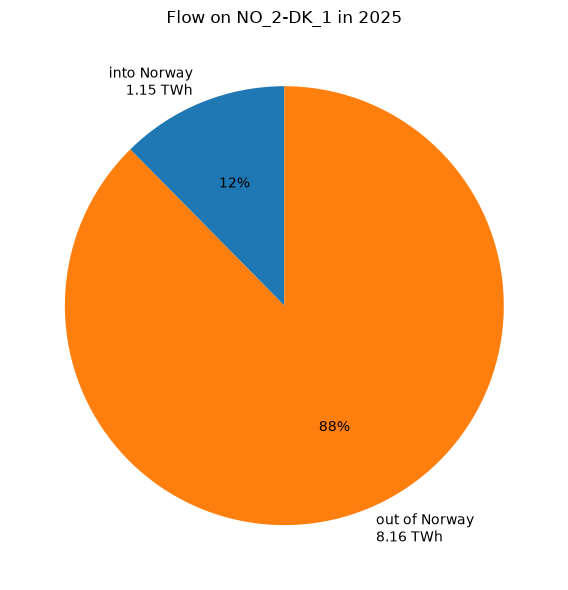

In [26]:
# Pie chart: total flow in and out of Norway for one connection over one year
CONNECTION = "NO_2-DK_1"   # any of the connections in CONNECTIONS, e.g. "NO_1-SE_3"
YEAR = 2025                 # 2025 is the last complete year

one_year = daily[(daily["connection"] == CONNECTION) & (daily["date"].dt.year == YEAR)]
totals_twh = one_year.groupby("direction")["flow_mwh"].sum() / 1e6   # MWh -> TWh

fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(totals_twh,
       labels=[f"{d}\n{v:.2f} TWh" for d, v in totals_twh.items()],
       autopct="%1.0f%%", startangle=90)
ax.set_title(f"Flow on {CONNECTION} in {YEAR}")
plt.tight_layout()
plt.show()

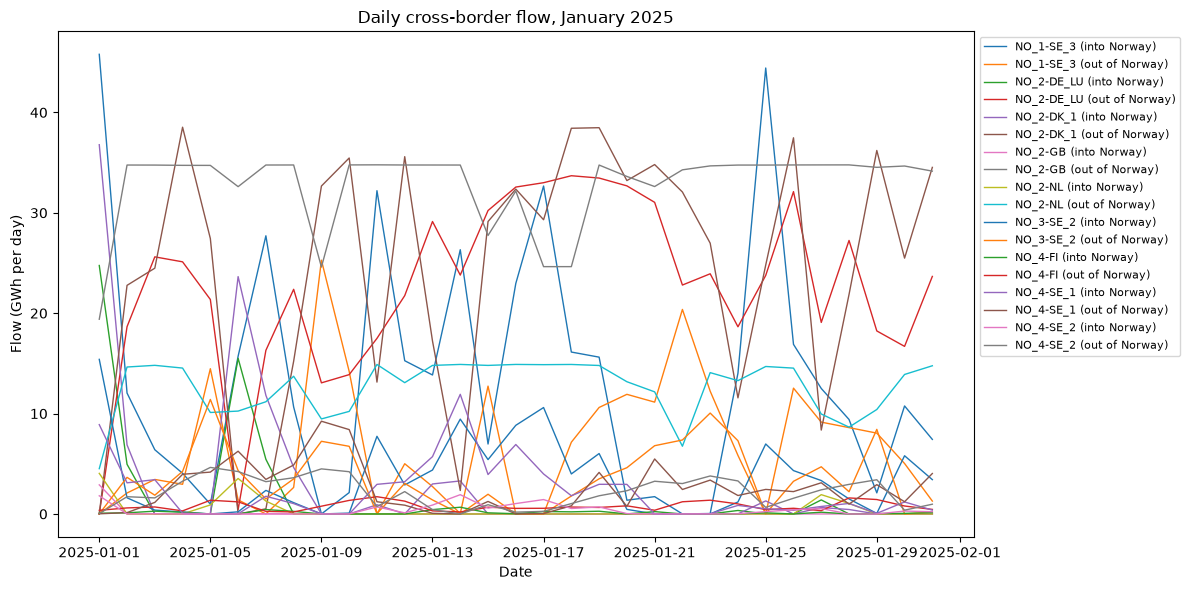

In [27]:
# Line plot: daily flow in January of the chosen year, one line per connection and direction
january = daily[(daily["date"].dt.year == YEAR) & (daily["date"].dt.month == 1)]

fig, ax = plt.subplots(figsize=(12, 6))
for (conn, direction), g in january.groupby(["connection", "direction"]):
    ax.plot(g["date"], g["flow_mwh"] / 1000, label=f"{conn} ({direction})", linewidth=1)
ax.set_title(f"Daily cross-border flow, January {YEAR}")
ax.set_xlabel("Date")
ax.set_ylabel("Flow (GWh per day)")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1), fontsize=8)
plt.tight_layout()
plt.show()

In [28]:
# Store the daily, Spark-curated data in MongoDB for the Streamlit app.
# Daily values (~18,000 documents) instead of hourly (~400,000) keep the app fast
# and stay well inside the free MongoDB tier.
collection = mdb["crossborder_daily"]
collection.drop()                                   # start fresh so re-runs don't duplicate
collection.insert_many(daily.to_dict("records"))
collection.create_index([("connection", 1), ("date", 1)])   # fast lookups from the app

print("Documents in MongoDB:", collection.count_documents({}))
print(collection.find_one({}, {"_id": 0}))

Documents in MongoDB: 18396
{'connection': 'NO_1-SE_3', 'from_zone': 'SE_3', 'to_zone': 'NO_1', 'date': datetime.datetime(2024, 1, 1, 0, 0), 'flow_mwh': 36698.82, 'direction': 'into Norway'}


## AI usage



## Log

